In [1]:
import base

import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm_notebook as tqdm
import torch

from data.gbm import GBM
import tensor_algebra as ta
import iisignature
import problem1
import optimiser_new
from math import factorial

C:\Users\muham\anaconda3\lib\site-packages\torch\__init__.py:696: UserWarning: torch.set_default_tensor_type() is deprecated as of PyTorch 2.1, please use torch.set_default_dtype() and torch.set_default_device() as alternatives. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\builder\windows\pytorch\torch\csrc\tensor\python_tensor.cpp:453.)
  _C._set_default_tensor_type(t)


In [2]:
sigma_s = 1e-1
b2 = 1e-3
a1 = -1

params = {'a0': 0, 'a1': a1, 'a2': 0, 'b0': 0, 'b1': 1, 'b2': b2,
              'sigma_alpha': 1, 'sigma_alpha_0': 0, 'sigma_s': sigma_s, 'k': 1e-3, 
              'theta1': 1, 'theta2': 1e-2, 'alpha0': 0, 'S0': 100, 'Q0': 10, 'X0': 0, 
              'T': 0.10, 'Nt': 1_000}

env_baseline = problem1.environment(**params)

In [3]:
np.random.seed(123)

nsims = 100

env_baseline.simulate(nsims, env_baseline.optimal_strag)

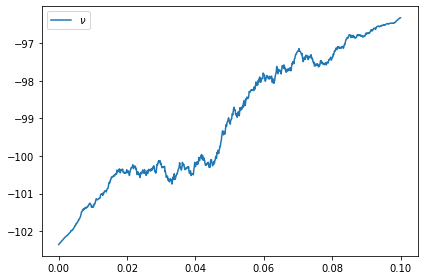

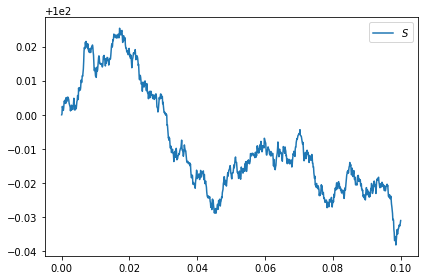

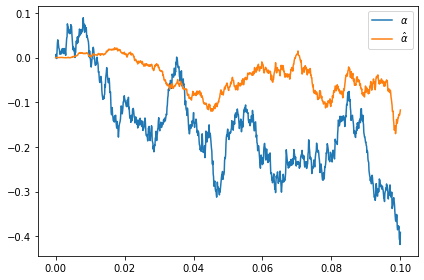

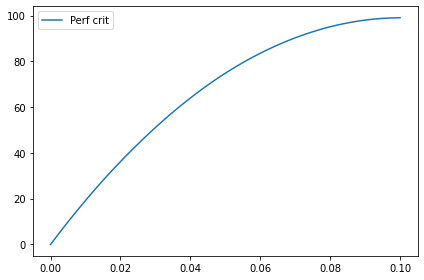

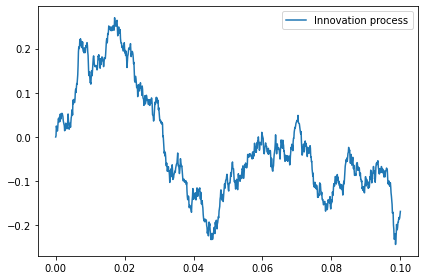

In [4]:
nsim = 2

plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.S[:,nsim], label=r'$S$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env_baseline.timesteps, env_baseline.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.run_crit[:,nsim], label=r'Perf crit')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env_baseline.timesteps, env_baseline.innov[:,nsim], label=r'Innovation process')
plt.legend()
plt.tight_layout()
plt.show()

In [5]:
env_baseline.wealth[-1,:].mean()

998.9934055184966

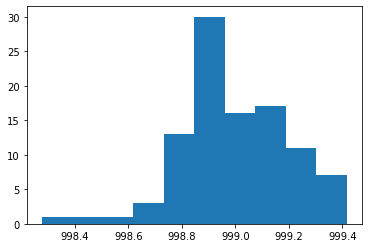

In [6]:
plt.hist(env_baseline.wealth[-1,:])
plt.show()

In [7]:
np.random.seed(456)
dim = 2
order = 5
poly_deg = 5

env = problem1.environment(**params)
optimiser_1 = optimiser_new.Optimiser(env, order = order, poly_deg = poly_deg)

In [8]:
optimiser_1.W_sig_expected

Tensor([1.0, [0.10000000000000002, -0.0025338081790085595], [[0.004999999999999978, -0.00016282989150851412], [-9.055092639234235e-05, 0.04944347702985092]], [[[0.0001666666666666665, -5.32789602724655e-06], [-5.627197096358251e-06, 0.0024619860881416942]], [[-1.7139477714379774e-06, -1.9997561188000335e-05], [0.0025023591760313987, -0.00020063512403147588]]], [[[[4.16666666666665e-06, -1.2041512662204082e-07], [-1.7154422285853362e-07, 8.249577217957243e-05]], [[-1.0981563195937843e-07, -1.6390729152368086e-06], [8.284613737026084e-05, -6.900681993872111e-06]]], [[[-2.052638172813996e-08, -1.7757114535482937e-07], [-5.540912853572478e-09, 3.392067018994773e-06]], [[8.369766057286631e-05, -7.031635256675764e-06], [-9.523262171594505e-06, 0.0012153172824003232]]]], [[[[[8.333333333333331e-08, -2.0768376295413755e-09], [-3.734162144038646e-09, 2.0740299485053333e-06]], [[-2.975967926868731e-09, -4.0089538294955496e-08], [2.0675769107362116e-06, -1.5494627187152424e-07]]], [[[-1.676542447

In [61]:
np.random.seed(456)
trunc_lev = 4
trunc_lev_1 = 4
n_epochs = 1000
lr = 0.1

optimiser_1.train_sgd(n_epochs, lr = lr, trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1, method='SGD')

F = optimiser_1.F
#-0.00322378
# F = np.array([0,  0.09357937,  0.00976083,  0.50394527,  0.14328703,
#         0.01977786,  0.43187132,  1.97467291, -2.06643172, -1.00965224,
#         0.21410011, -1.31586643,  1.06797256, -0.4782838 ,  1.35956328,
#        -0.14965823, -0.91161901,  1.07575663, -0.32765979, -1.51721624,
#         0.71442782,  0.43418935,  0.87081869,  0.85600043,  0.68956403,
#         0.89171545, -0.58705816, -0.02064186, -0.08605073, -0.25035624,
#        -1.26631587, -0.0792185 ,  0.9421223 ,  2.2838153 , -1.98716938,
#        -1.04700991, -0.66656956,  0.85822764, -0.19099187,  0.00411707,
#         0.44560233,  0.85724834,  0.98372921, -0.07301021, -1.12517175,
#        -1.39426226,  1.7228998 ,  0.34158784, -0.04832977, -0.40840225,
#        -0.27124056,  1.03903551,  0.86156363, -0.57254328,  1.05701483,
#         1.84432608,  1.26599393,  0.89605829,  1.35632508, -1.00645937,
#         1.13841291, -0.70447754, -0.43444132,  0.57876777,  0.21273156,
#         0.09356639, -0.51897783, -1.52636097,  1.25910536, -1.11400462,
#         1.49299764, -0.1371667 ,  1.51676821,  0.38691939, -0.76658046,
#         0.63663156,  0.41123621, -1.13188433,  0.3752521 ,  1.87456348,
#         1.00731224, -0.55313612,  2.17501185, -2.06996846, -1.02598605,
#         0.00818857, -0.45864387,  0.09906513,  0.28966562,  0.60524738,
#         1.91412556, -0.19252796, -0.77637316,  0.89276947, -1.82597895,
#        -0.21433314, -0.76157718, -0.67508898,  0.26232955, -0.57130935,
#         0.97023881,  1.97967367, -0.63595128, -2.19466954, -0.52922945,
#         1.9081074 ,  1.83940976, -1.27900779, -1.39325514, -0.38638011,
#        -0.40415115,  0.25431475, -0.80743413,  0.54509615,  1.0183611 ,
#        -0.2601938 , -0.5142783 ,  0.61318538, -0.79793486, -0.50247488,
#         0.16723857,  0.35045687, -0.71726866,  0.37842003,  0.89655428,
#        -1.33295125, -0.75624467])

# F = ta.sig_to_tensor(F, dim = dim, order = order)

strag_sig = problem1.sig_strag_dot(F, order = order)

[99.01263909]: 100%|███████████████████████████████████████████████████████████████| 1000/1000 [07:48<00:00,  2.13it/s]


In [62]:
import pickle

with open('params.pkl', 'wb') as f:
    pickle.dump(params, f)
    f.close()
    
with open('F_optimised.pkl', 'wb') as f:
    pickle.dump(F.flatten(), f)
    f.close()

In [63]:
strag_sig = problem1.sig_strag_dot(F, order = order)

In [64]:
F.flatten()

array([-9.86440578e+01, -5.74850878e+00,  7.92079242e-02,  1.87308306e-01,
        1.88064363e+00, -2.06413347e+00, -2.32086670e+00,  8.58860478e-02,
        1.32343008e+00,  6.02350566e-01, -1.35690243e+00,  5.27054673e-01,
       -1.22156520e+00, -1.37317186e+00, -5.12737850e-01,  2.27132626e-01,
        4.30221690e-01, -1.54556552e+00, -5.86176325e+00, -4.10336974e-01,
       -5.16001574e-01, -4.63189036e+00,  2.92195801e+00, -5.59745091e-01,
        1.53053001e+00,  1.28488763e+00,  5.68855516e-01, -5.42155259e+00,
        7.17262773e-01,  1.97287791e+00, -1.05080255e+02,  4.59161731e-01,
        1.61348259e+00, -1.18270196e+00, -4.74765745e-01,  1.03511270e+00,
       -3.40754870e-01,  5.73807769e-01,  6.33788800e-01, -1.11588841e+00,
       -7.61114396e-02, -9.80877701e-01,  1.13671838e+00, -5.71708869e-01,
        6.75803496e-01, -1.65924580e+00, -2.60324285e-01, -1.50020635e+00,
       -3.27447689e-01, -6.87580575e-02,  8.05585432e-01,  1.17519486e-01,
        9.12329289e-01,  

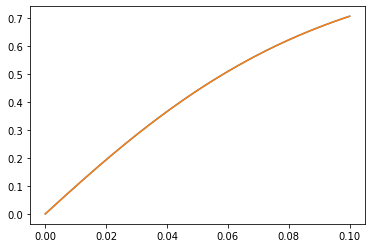

In [65]:
sigma_alpha_hat = env.b1*env.V_alpha/env.sigma_s
p_coef = np.polyfit(env.timesteps, sigma_alpha_hat, deg = poly_deg)
sigma_alpha_hat_fit = np.polyval(p_coef, env.timesteps)
plt.plot(env.timesteps, sigma_alpha_hat)
plt.plot(env.timesteps, sigma_alpha_hat_fit)

In [66]:
factorials = np.array([factorial(i) for i in range(poly_deg + 1)])

p_coef_reversed = p_coef[::-1]*factorials

In [67]:
p_coef[::-1]

array([ 4.15396971e-05,  9.98093165e+00, -7.93096893e+00, -4.16634875e+02,
        2.49885785e+03, -4.58523394e+03])

In [89]:
f_s = ta.word((),dim)*env.alpha0 + F*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
# word = (1,)
# for k in range(len(p_coef_reversed)):
#     word_tensor = ta.word(word,dim)
#     f_s += word_tensor*p_coef_reversed[k]
#     word = (0,) + word
f_s += optimiser_1.vol_sig
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev)
f_s = f_s*exp_a1
f_s = f_s*(ta.word((0,),dim)*env.b1)
f_s += ta.word((1,),dim)*env.sigma_s
f_s += ta.word((0,),dim)*env.b0
f_s += (F + optimiser_1.e0*env.Q0)*(ta.word((0,),dim)*env.b2)
f_s += ta.word((),dim)*env.S0 
f_s = f_s.truncate(trunc_lev)

f_alpha = ta.word((),dim)*env.alpha0 + (F + optimiser_1.e0*env.Q0)*ta.word((0,),dim)*env.a2 + ta.word((0,),dim)*env.a0
word = (1,)
# for k in range(len(p_coef_reversed)):
#     word_tensor = ta.word(word,dim)
#     f_alpha += word_tensor*p_coef_reversed[k]
#     word = (0,) + word
f_alpha += optimiser_1.vol_sig
exp_a1 = (ta.word((0,),dim)*env.a1).exp(MAX_ITER = 200, MAX_LEVEL = trunc_lev_1)
f_alpha = f_alpha*exp_a1
f_alpha = f_alpha.truncate(trunc_lev_1)

M_max = F.order
#M_max = 2*F.order
p_perf = -F.shuffle(F, max_order = M_max)
p_perf = p_perf*(optimiser_1.e1*optimiser_1.env.k)
#M_max = (F*optimiser_1.e1).order + F.order
p_perf += ((F*optimiser_1.e1 + optimiser_1.e0*env.Q0).shuffle(F, max_order = M_max))*(optimiser_1.e1*(optimiser_1.env.b2 - 2*optimiser_1.env.theta1))
#M_max = (F*optimiser_1.e1).order + trunc_lev_1
p_perf += ((F*optimiser_1.e1 + optimiser_1.e0*env.Q0).shuffle(f_alpha, max_order = M_max))*(optimiser_1.e1*optimiser_1.env.b1)
p_perf += ((F*optimiser_1.e1 + optimiser_1.e0*env.Q0)*(optimiser_1.e1*optimiser_1.env.b0))
F_prod_e1 = F*optimiser_1.e1
#M_max = 2*F_prod_e1.order
p_perf -= (F_prod_e1.shuffle(F_prod_e1, max_order = M_max) + F_prod_e1*optimiser_1.e0*env.Q0 + optimiser_1.e0*F_prod_e1*env.Q0 + optimiser_1.e0*env.Q0**2)*(optimiser_1.e1*optimiser_1.env.theta2)
p_perf = p_perf.truncate(optimiser_1.order)

In [69]:
np.random.seed(123)

nsims = 100

env.simulate(nsims, strag_sig)

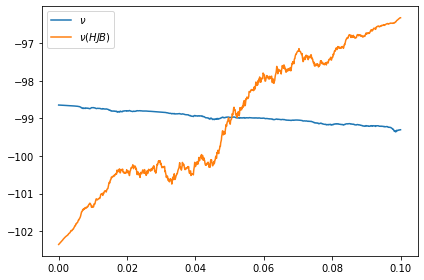

In [70]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

In [71]:
print(f'Performance criterion\nSig: {env.run_crit[-1,:].mean()}, HJB: {env_baseline.run_crit[-1,:].mean()}')
print(f'Wealth\nSig: {env.wealth[-1,:].mean()}, HJB: {env_baseline.wealth[-1,:].mean()}')

Performance criterion
Sig: 99.02357490827144, HJB: 99.02442329457807
Wealth
Sig: 998.9933155152619, HJB: 998.9934055184966


In [72]:
optimiser_1.value_fn(F.flatten(), trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

-99.01263920732077

In [74]:
F

Tensor([-98.64405783793804, [-5.748508776459803, 0.07920792416338313], [[0.1873083061025226, 1.880643625222582], [-2.064133467906074, -2.3208666959815782]], [[[0.08588604780860856, 1.323430082387702], [0.6023505660087805, -1.3569024283558166]], [[0.5270546729301212, -1.221565200497808], [-1.3731718598950753, -0.5127378504062141]]], [[[[0.22713262561000075, 0.4302216897747455], [-1.5455655158186314, -5.861763250467495]], [[-0.41033697362468713, -0.516001573610527], [-4.631890362587266, 2.9219580085385535]]], [[[-0.5597450906348349, 1.5305300091419718], [1.284887633763999, 0.5688555162455049]], [[-5.421552585808494, 0.7172627733542021], [1.9728779055764067, -105.08025549469097]]]], [[[[[0.459161730960264, 1.613482587433324], [-1.1827019554984024, -0.47476574518535575]], [[1.0351127020889193, -0.34075487001868526], [0.5738077689857998, 0.63378880041051]]], [[[-1.1158884121252959, -0.07611143962682966], [-0.9808777007345375, 1.1367183827770146]], [[-0.5717088688394423, 0.6758034956462434],

In [90]:
# f_s_sig = problem1.sig_strag_dot_1(f_s, order = trunc_lev)
# f_alpha_sig = problem1.sig_strag_dot_1(f_alpha, order = trunc_lev_1)
# f_perf_crit = problem1.sig_strag_dot_1(p_perf, order = order)

f_s_sig = problem1.sig_strag_dot(f_s, order = trunc_lev)
f_alpha_sig = problem1.sig_strag_dot(f_alpha, order = trunc_lev_1)
f_perf_crit = problem1.sig_strag_dot(p_perf, order = order)

S_sig = np.zeros((env.Nt+1,nsims))
alpha_hat_sig = np.zeros((env.Nt+1,nsims))
perf_hist = np.zeros((env.Nt+1,nsims))

# S_sig = f_s_sig(env)
# alpha_hat_sig = f_alpha_sig(env)
# perf_hist = f_perf_crit(env)

for it in range(env.Nt+1):
    S_sig[it,:] = f_s_sig(env,it)
    alpha_hat_sig[it,:] = f_alpha_sig(env,it)
    perf_hist[it,:] = f_perf_crit(env,it)
    #S_sig[it,:] = strag_sig(env,it)

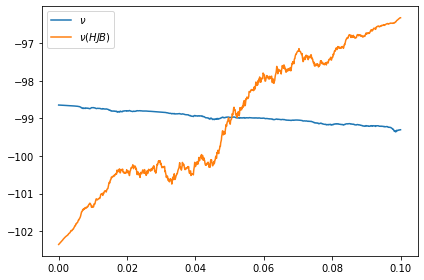

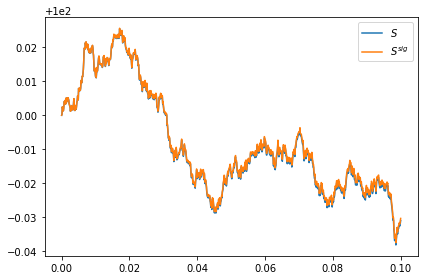

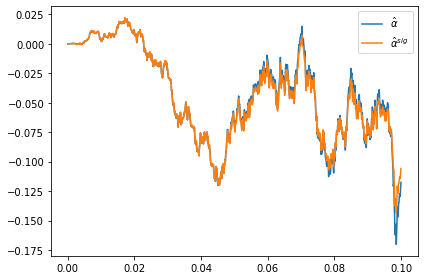

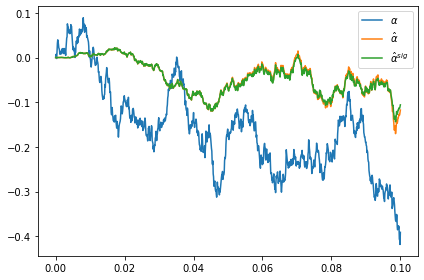

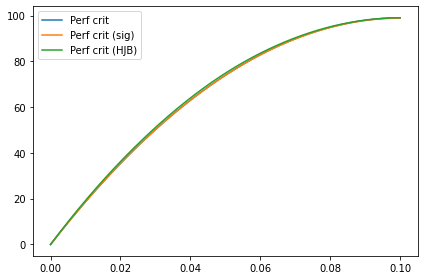

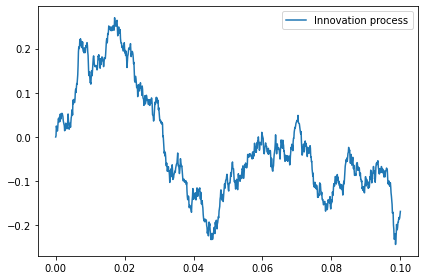

In [92]:
nsim = 2

plt.plot(env.timesteps, env.nu[:,nsim], label=r'$\nu$')
plt.plot(env_baseline.timesteps, env_baseline.nu[:,nsim], label=r'$\nu (HJB)$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.S[:,nsim], label=r'$S$')
plt.plot(env.timesteps, S_sig[:,nsim], label=r'$S^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps[:], alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.alpha[:,nsim], label=r'$\alpha$')
plt.plot(env.timesteps, env.alpha_hat[:,nsim], label=r'$\hat{\alpha}$')
plt.plot(env.timesteps, alpha_hat_sig[:,nsim], label=r'$\hat{\alpha}^{sig}$')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps[:], env.run_crit[:,nsim], label=r'Perf crit')
plt.plot(env.timesteps[:], perf_hist[:,nsim], label=r'Perf crit (sig)')
plt.plot(env_baseline.timesteps[:], env_baseline.run_crit[:,nsim], label=r'Perf crit (HJB)')
plt.legend()
plt.tight_layout()
plt.show()

plt.plot(env.timesteps, env.innov[:,nsim], label=r'Innovation process')
plt.legend()
plt.tight_layout()
plt.show()

In [87]:
env.run_crit[-1,:]

array([99.02416545, 99.02390128, 99.02399443, 99.02417257, 99.02392456,
       99.02391914, 99.02411325, 99.02391699, 99.02398697, 99.02417472,
       99.02407262, 99.02391291, 99.02415765, 99.02390913, 99.02419492,
       99.02395693, 99.02390698, 99.02419433, 99.02412916, 99.0240309 ,
       99.02393775, 99.02397085, 99.02403463, 99.02102889, 99.02389538,
       99.02409432, 99.02409958, 99.02420527, 99.02397411, 99.02389514,
       99.02396297, 99.02348647, 99.02411545, 99.02393191, 99.02391427,
       99.02416267, 99.02401681, 99.02399896, 99.02408684, 99.02418224,
       99.02389459, 99.02399331, 99.02389668, 99.02404679, 99.0240527 ,
       99.02405656, 99.02398555, 99.0241895 , 99.02421455, 99.02394822,
       99.02400694, 99.02411913, 99.02418965, 99.02396943, 99.02392757,
       99.02390359, 99.02390891, 99.02405863, 99.02389728, 99.02394495,
       98.99136422, 99.02397507, 99.02405464, 99.02392299, 99.02389085,
       99.0240105 , 99.02392737, 99.02401378, 99.0239757 , 99.02

In [34]:
env.Q[-1,:]

array([10.00083394, 10.00054017,  9.99977901,  9.99913974,  9.99992792,
        9.99986669,  9.99997022,  9.99985589, 10.00006201, 10.00065353,
        9.99926519, 10.00064421, 10.00082784, 10.00038033, 10.00077396,
        9.99969391, 10.00005985, 10.00058713,  9.99940915,  9.99943079,
       10.0003252 ,  9.99962252,  9.99952188, 10.00051339,  9.99993523,
        9.99921895,  9.99921199, 10.00066157, 10.00086916, 10.00050949,
        9.99960262,  9.99976577,  9.99938747,  9.99985755, 10.0000812 ,
       10.00076215, 10.00047731,  9.99943836, 10.00063357, 10.00057497,
       10.000001  ,  9.99956432, 10.00039978, 10.00092967,  9.99931345,
       10.00084701,  9.9997866 ,  9.99910342, 10.00066291, 10.00023357,
        9.99969451, 10.00096904,  9.99918548, 10.00080378, 10.00038089,
        9.99996408,  9.99987481,  9.9993053 , 10.00027454, 10.00081015,
       10.00527712,  9.99965584, 10.00042261, 10.00061637, 10.00034151,
        9.99974223,  9.9996983 , 10.00072388,  9.99976818,  9.99

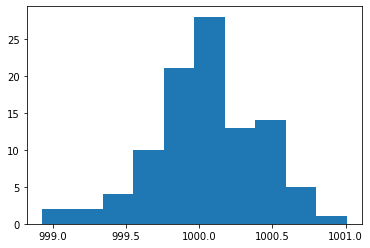

In [33]:
plt.hist(env.wealth[-1,:])
plt.show()

In [20]:
env.run_crit[-1,:].mean()

-0.10318310920213757

In [21]:
env_baseline.run_crit[-1,:].mean()

99.02442329457807

In [12]:
-optimiser_1.value_fn(F.flatten(), trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

-0.0028252369008055834

In [23]:
perf_hist[-1,:].mean()

2.4316982244910558e-06

In [24]:
p_perf.order

5

In [25]:
path_sig_sim = np.zeros((2**(order+1) - 2, nsims))
for nsim in range(nsims):
    path = np.array([env.timesteps,env.innov[:, nsim]]).T
    path_sig = iisignature.sig(path, order)
    path_sig_sim[:, nsim] = path_sig
mean_sig = np.mean(path_sig_sim, axis=1)
mean_sig = np.insert(mean_sig, 0, 1)
mean_sig = ta.sig_to_tensor(mean_sig, dim = 2, order = order)

In [26]:
mean_sig.dot(p_perf)

tensor([2.4317e-06])

In [27]:
p_perf.dot(mean_sig)

tensor([2.4317e-06])

In [28]:
optimiser_1.value_fn(F.flatten(), trunc_lev_s = trunc_lev, trunc_lev_alpha_hat = trunc_lev_1)

-1.9329308787532657e-06

In [29]:
optimiser_1.p_perf.dot(mean_sig)

tensor([2.4317e-06])

In [30]:
perf_hist.shape

(1001, 100)

In [31]:
env.run_crit.shape

(1001, 100)

In [32]:
F.flatten()

array([ 0.05444246, -1.10888757,  0.06604797,  1.79740425,  0.23087973,
       -0.24842512, -0.06003007,  0.89160997,  0.03118972, -0.41140799,
       -0.98132101,  0.2152381 ,  0.41243674,  0.37356268, -1.37984312,
        0.89483676,  0.42478405, -0.0443411 , -0.30914909,  0.45655516,
        0.10148216, -0.30536785,  0.55801414,  1.02417152, -1.60920159,
        0.41185207, -2.12137226,  0.47101342, -0.21258209, -1.12114565,
        0.49044315, -0.25953187, -0.05670704, -0.55216047, -0.08093759,
        1.56312372,  0.36847265,  1.10480118,  0.22260521, -0.08115625,
       -0.78764205, -1.36630435, -1.19665387, -0.02412159, -0.47128173,
       -0.78927171,  0.70738473, -0.34496413,  0.73520916, -1.1640528 ,
        1.24927386, -0.04850225, -0.15084257,  0.70183163,  0.67542115,
        0.48649668, -1.35455666, -0.82570987,  0.9832603 , -0.62704161,
       -0.73767822,  0.01464198, -1.31733377])

In [35]:
env_baseline.Q[-1,:]

array([0.09849106, 0.09775964, 0.09636304, 0.09545701, 0.09693491,
       0.09763132, 0.09988047, 0.09829434, 0.09655483, 0.09888499,
       0.09682977, 0.0975887 , 0.09875647, 0.09811854, 0.09856239,
       0.09715401, 0.09704959, 0.09961113, 0.09741221, 0.09649707,
       0.09692696, 0.09696978, 0.09613955, 0.09466688, 0.09735459,
       0.0963914 , 0.09604575, 0.09852772, 0.09825808, 0.09770443,
       0.0967868 , 0.0989758 , 0.09577679, 0.09758432, 0.09716917,
       0.09900843, 0.09702236, 0.09656763, 0.09924836, 0.09936615,
       0.09744973, 0.09660801, 0.09855908, 0.09854512, 0.09546005,
       0.09804988, 0.09639332, 0.09680261, 0.09801427, 0.09693917,
       0.09631145, 0.09801333, 0.09578159, 0.09803228, 0.09732927,
       0.0973637 , 0.09779852, 0.09664477, 0.09770643, 0.09795613,
       0.09464192, 0.09672782, 0.09923735, 0.09823299, 0.09772199,
       0.09600657, 0.09714149, 0.09885171, 0.09641684, 0.09638712,
       0.10055403, 0.09700445, 0.09529952, 0.09950042, 0.09984

In [37]:
optimiser_1.F.value

[tensor(0.0544),
 tensor([-1.1089,  0.0660]),
 tensor([[ 1.7974,  0.2309],
         [-0.2484, -0.0600]]),
 tensor([[[ 0.8916,  0.0312],
          [-0.4114, -0.9813]],
 
         [[ 0.2152,  0.4124],
          [ 0.3736, -1.3798]]]),
 tensor([[[[ 0.8948,  0.4248],
           [-0.0443, -0.3091]],
 
          [[ 0.4566,  0.1015],
           [-0.3054,  0.5580]]],
 
 
         [[[ 1.0242, -1.6092],
           [ 0.4119, -2.1214]],
 
          [[ 0.4710, -0.2126],
           [-1.1211,  0.4904]]]]),
 tensor([[[[[-0.2595, -0.0567],
            [-0.5522, -0.0809]],
 
           [[ 1.5631,  0.3685],
            [ 1.1048,  0.2226]]],
 
 
          [[[-0.0812, -0.7876],
            [-1.3663, -1.1967]],
 
           [[-0.0241, -0.4713],
            [-0.7893,  0.7074]]]],
 
 
 
         [[[[-0.3450,  0.7352],
            [-1.1641,  1.2493]],
 
           [[-0.0485, -0.1508],
            [ 0.7018,  0.6754]]],
 
 
          [[[ 0.4865, -1.3546],
            [-0.8257,  0.9833]],
 
           [[-0.6270, -